Montar Drive e localizar pasta correta

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [23]:
import os
os.chdir('/content/drive/MyDrive/Mestrado/Aprendizado de Máquina/DecisionTree')

In [ ]:
print(os.getcwd())
!ls

/content/drive/MyDrive/Aprendizado de Máquina/DecisionTree
pima-indians-diabetes.csv


Importar Bibliotecas

In [ ]:
import pandas as pd
import numpy as np

Ler arquivo CSV

In [ ]:
colunas = [
    "Pregnancies",
    "Glucose",
    "BloodPressure",
    "SkinThickness",
    "Insulin",
    "BMI",
    "DiabetesPedigreeFunction",
    "Age",
    "Outcome"
]

df = pd.read_csv('pima-indians-diabetes.csv', header = None, names=colunas)

df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


## Tratamento de Outliers
- Winsorização: limita os valores extremos aos percentis 1% e 99%.
- Método do IQR: identifica e remove ou limita valores fora de 1,5×IQR.

## Tratar valores zero

1. Imputar com Mediana por Classe

2. Imputar com KNNImputer

## Engenharia de Atributos
- Faixas de idade: categorizar Age e BMI (por exemplo, faixas clínicas de IMC).
- Razões e interações: como Glucose * BMI ou Insulin / Glucose.
- Indicadores de ausência: colunas binárias marcando que o valor era faltante (às vezes o próprio fato de não ter medido a insulina é informativo).
- Variáveis binárias: como Pregnancies > 0.



## Balanceamento de Classes
- class_weight='balanced': a mais simples, sem alterar os dados.
- SMOTE: gera exemplos sintéticos da classe minoritária (biblioteca imbalanced-learn).

## Seleção de atributos
- feature_importances_ da própria árvore para identificar o que pesa mais.
- Correlação: remover variáveis muito correlacionadas entre si.
- SelectKBest ou RFE para escolher um subconjunto.

Nesta base, Glucose, BMI e Age costumam ser as mais relevantes.

## Validação e Ajuste
- Validação cruzada estratificada (StratifiedKFold) em vez de um único split, porque a base tem só 768 linhas.
- GridSearchCV para max_depth, min_samples_leaf, min_samples_split e ccp_alpha (poda).
- Métricas além da acurácia: recall, F1 e AUC-ROC.

## Treinamento do Modelo

In [ ]:
# Árvore de decisão básica
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import accuracy_score, classification_report
import matplotlib.pyplot as plt

X = df.drop('Outcome', axis=1)
y = df['Outcome']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

modelo = DecisionTreeClassifier(max_depth=4, random_state=42)
modelo.fit(X_train, y_train)

y_pred = modelo.predict(X_test)
print("Acurácia:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Acurácia: 0.7662337662337663
              precision    recall  f1-score   support

           0       0.80      0.85      0.83       150
           1       0.69      0.60      0.64        81

    accuracy                           0.77       231
   macro avg       0.75      0.73      0.74       231
weighted avg       0.76      0.77      0.76       231



Visualizar a árvore




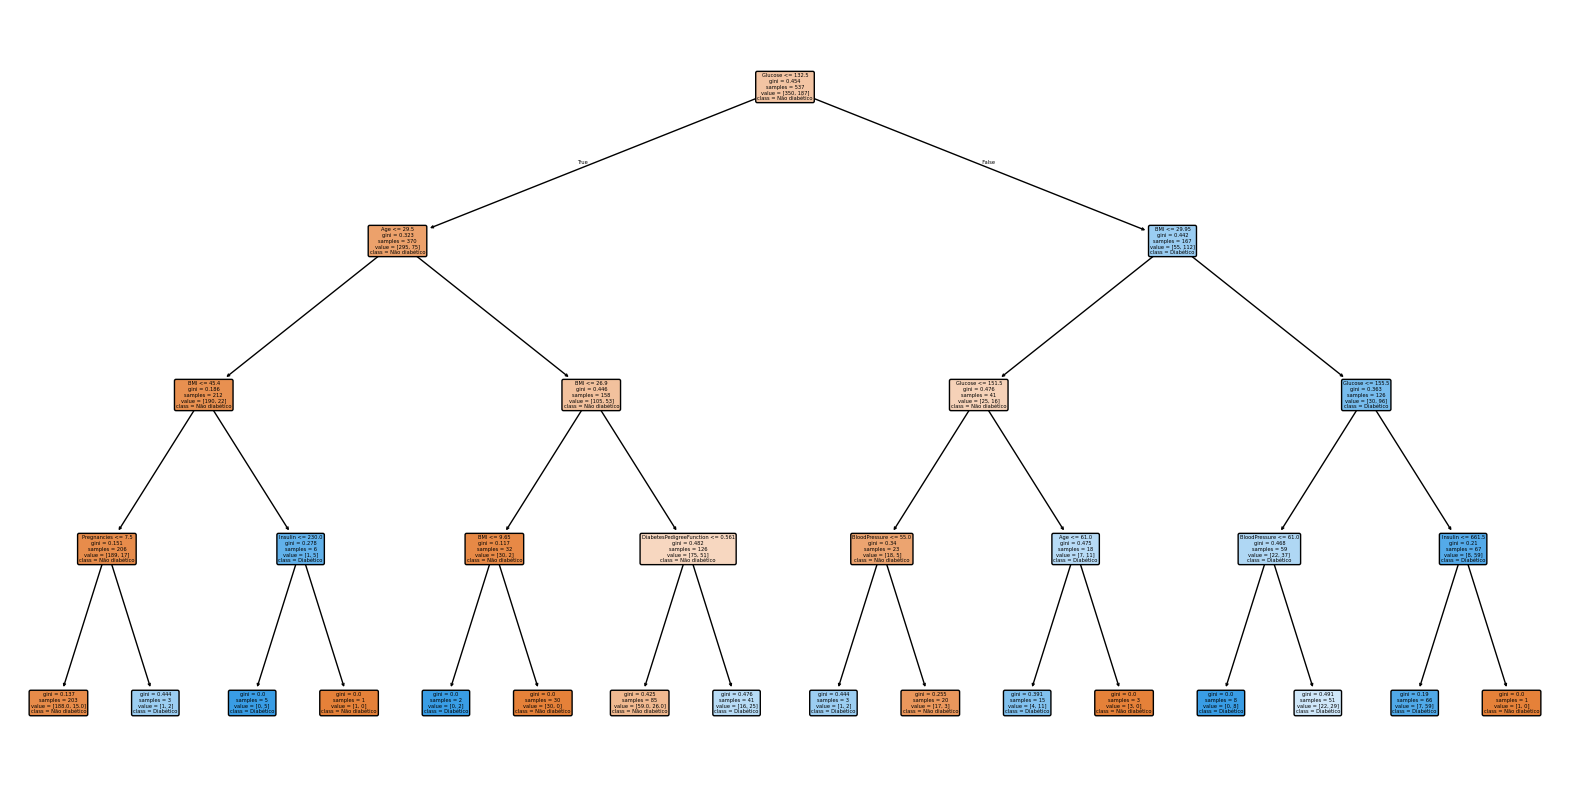

In [ ]:
plt.figure(figsize=(20, 10))
plot_tree(modelo, feature_names=X.columns, class_names=['Não diabético', 'Diabético'],
          filled=True, rounded=True)
plt.show()